# 02 — Volume Exchange

Compute the volume exchange distance between grain-labeled windows with `VolumeExchange`:
1. A pairwise dissimilarity matrix between windows from two classes.
2. A visualization of which grains are matched in the optimal assignment.

In [1]:
# ======== Library Imports ========
import numpy as np
import sys
sys.path.append('../src')
from Volume_Exchange import VolumeExchange

In [2]:
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

In [3]:
# ======== Load Windows ========
data = np.load('../example_data/window_dataset.npz')
print(data.files)

class_a, class_b = 'EI1', 'BI1'
n = 10  # windows per class

rng = np.random.default_rng(0)
A = data[class_a][rng.choice(len(data[class_a]), n, replace=False)]
B = data[class_b][rng.choice(len(data[class_b]), n, replace=False)]
windows = np.concatenate([A, B])  # (2n, 20, 20)
print(windows.shape)

['EI1', 'EI2', 'EII1', 'EII2', 'BII1', 'BII2', 'RI1', 'RI2', 'BI1', 'BI2']
(20, 20, 20)


## 1. Pairwise Dissimilarity Matrix

Rows/cols `0..n-1` are windows from `class_a`, `n..2n-1` from `class_b`. Volume exchange is symmetric, so only the upper triangle is computed.

In [4]:
# ======== Pairwise Volume Exchange ========
D = np.zeros((2 * n, 2 * n))
for i in range(2 * n):
    for j in range(i + 1, 2 * n):
        D[i, j] = D[j, i] = VolumeExchange(windows[i], windows[j])

print(f'mean within {class_a}: {D[:n, :n][np.triu_indices(n, 1)].mean():.3f}')
print(f'mean within {class_b}: {D[n:, n:][np.triu_indices(n, 1)].mean():.3f}')
print(f'mean between:      {D[:n, n:].mean():.3f}')

mean within EI1: 0.484
mean within BI1: 0.552
mean between:      0.558


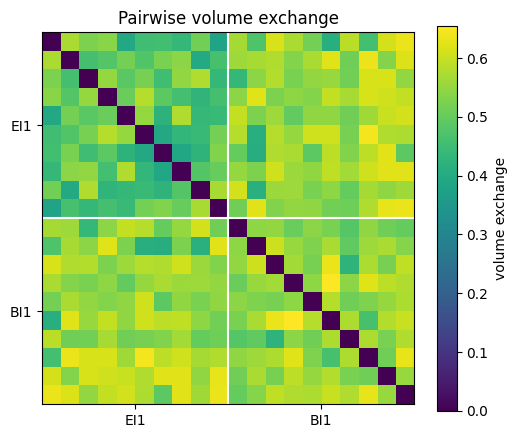

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(D, cmap='viridis')
ax.axhline(n - 0.5, color='w', lw=1.5)
ax.axvline(n - 0.5, color='w', lw=1.5)
ax.set_xticks([n / 2 - 0.5, 3 * n / 2 - 0.5], [class_a, class_b])
ax.set_yticks([n / 2 - 0.5, 3 * n / 2 - 0.5], [class_a, class_b])
ax.set_title('Pairwise volume exchange')
fig.colorbar(im, ax=ax, label='volume exchange')
plt.show()

## 2. Matched vs. Unmatched Grains

Each grain in both windows gets a unique prime, so multiplying the two windows gives the overlaid structure `X`: its grains are the intersections of grains from `M` and `N` (the union of both sets of grain boundaries). The overlap area of optimally matched grain pairs is shown in white, everything else in gray. The white area fraction equals `1 - volume exchange`.

In [6]:
def draw_boundaries(ax, img, color='k', lw=1):
    """Draw pixel-edge lines wherever neighboring labels differ."""
    rv, cv = np.nonzero(img[:, 1:] != img[:, :-1])
    rh, ch = np.nonzero(img[1:, :] != img[:-1, :])
    segs = [[(c + 0.5, r - 0.5), (c + 0.5, r + 0.5)] for r, c in zip(rv, cv)]
    segs += [[(c - 0.5, r + 0.5), (c + 0.5, r + 0.5)] for r, c in zip(rh, ch)]
    ax.add_collection(LineCollection(segs, colors=color, linewidths=lw))


def plot_matching(M_img, N_img, titles=('M', 'N')):
    cost, X_img, matched = VolumeExchange(M_img, N_img, return_overlay=True)

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, img, title in zip(axes[:2], (M_img, N_img), titles):
        ax.imshow(np.unique(img, return_inverse=True)[1].reshape(img.shape), cmap='tab20')
        draw_boundaries(ax, img)
        ax.set_title(title)

    axes[2].imshow(np.where(matched, 1.0, 0.5), cmap='gray', vmin=0, vmax=1)
    draw_boundaries(axes[2], X_img)
    axes[2].set_title(f'Overlay (VE = {cost:.3f})')
    for ax in axes:
        ax.set_xticks([]); ax.set_yticks([])
    plt.show()
    print(f'matched area = {matched.mean():.3f}, 1 - VE = {1 - cost:.3f}')

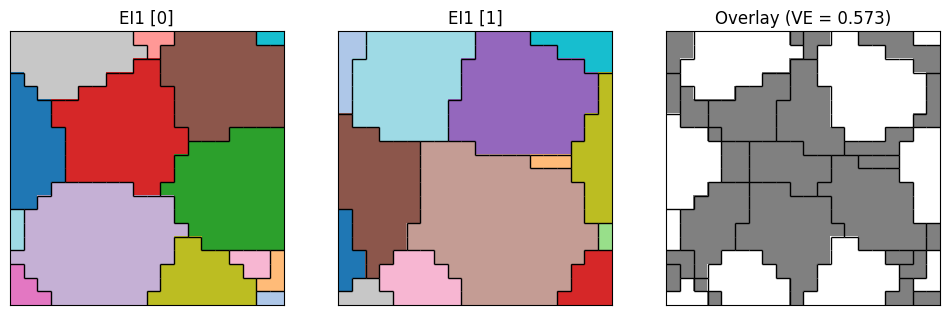

matched area = 0.427, 1 - VE = 0.427


In [7]:
# Within-class pair
plot_matching(A[0], A[1], titles=(f'{class_a} [0]', f'{class_a} [1]'))

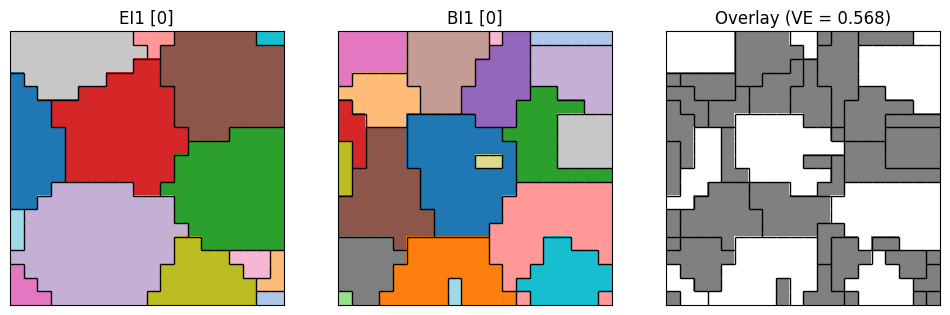

matched area = 0.432, 1 - VE = 0.432


In [8]:
# Between-class pair
plot_matching(A[0], B[0], titles=(f'{class_a} [0]', f'{class_b} [0]'))